In [1]:
%pip install pandas
%pip install pyarrow
%pip install fastparquet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# LEctura de datos 

In [2]:
import pandas as pd

df = pd.read_parquet('stuff_model_df.parquet',engine='fastparquet')


In [3]:
df.head(1)

,year,PitchUID,game_anon_id,pitcher_anon_id,batter_anon_id,catcher_anon_id,PitcherThrows,BatterSide,altitude_category,AutoPitchType,...,Top/Bottom,Outs,Balls,Strikes,count,PlateLocHeight,PlateLocSide,in_strike_zone,outside_strike_zone,swung_outside_strike_zone
0,2024,d6a82560-f939-11ee-8e28-698264036ef0,game_001331,pitcher_01067,batter_00272,catcher_00123,Left,Right,No Altitude,Sinker,...,Top,0.0,0.0,0.0,0-0,4.19842,-1.06959,0,1.0,0.0


In [4]:
print("tam del df", len(df))

tam del df 635002


In [6]:
import pandas as pd

dictionary = pd.read_csv('stuff_plus_data_dictionary.csv', sep=',')
print(dictionary.keys())

Index(['column_name', 'definition', 'data_type', 'unit_or_values', 'category',
       'feature_role', 'use_as_model_feature', 'notes'],
      dtype='object')


# DEsarrollo


## visualizar informacion de datos 

In [ ]:
dictionary_by_column = dictionary.set_index('column_name')

for column in df.columns:
    print('=' * 80)
    print(f'Column name: {column}')
    print(f'Data type: {df[column].dtype}')

    if column in dictionary_by_column.index:
        info = dictionary_by_column.loc[column]
        print(f"Definition: {info['definition']}")
        print(f"Unit or values: {info['unit_or_values']}")
        print(f"Feature role: {info['feature_role']}")
        print(f"Use as model feature: {info['use_as_model_feature']}")
        print(f"Notes: {info['notes']}")
    else:
        print('Definition: Not available in the data dictionary')
        print('Unit or values: Not available in the data dictionary')
        print('Feature role: Not available in the data dictionary')
        print('Use as model feature: Not available in the data dictionary')
        print('Notes: Not available in the data dictionary')

    unique_count = df[column].nunique(dropna=False)
    print(f'Unique value count: {unique_count}')
    if unique_count < 20:
        print('Unique values:')
        print(df[column].value_counts(dropna=False).to_string())
    else:
        print('Unique values: omitted')

Column name: year
Data type: int32
Definition: Season year extracted from the local pitch date.
Unit or values: YYYY
Feature role: context_only
Use as model feature: Yes, for season normalization or splits only
Notes: Derived from Trackman Date. Useful for train/test splits and season-level calibration.
Unique value count: 3
Unique values:
year
2025    256144
2024    243254
2026    135604
Column name: PitchUID
Data type: object
Definition: Unique pitch identifier for the pitch event.
Unit or values: GUID / unique ID
Feature role: id_only
Use as model feature: No
Notes: Use only to return predictions and join results back internally. Do not use as a model input.
Unique value count: 635002
Unique values: omitted because there are 20 or more
Column name: game_anon_id
Data type: object
Definition: Anonymous game identifier created by Diablos for the hackathon dataset.
Unit or values: game_######
Feature role: grouping_only
Use as model feature: No
Notes: Use for grouping, validation splits

## Visualizacion de algunos datos


### visualizar por donde paso un  pitcheo

In [135]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon


def plot_pitches(dataframe, batter_height=None, color_by='AutoPitchType'):
    if batter_height is not None:
        if 10 < batter_height < 300:
            batter_height_feet = batter_height / 30.48
        else:
            batter_height_feet = batter_height
        top_of_zone = batter_height_feet * 0.51
        bottom_of_zone = batter_height_feet * 0.22
    else:
        top_of_zone = 3.5
        bottom_of_zone = 1.6

    zone_width = 1.66
    zone_left = -zone_width / 2
    required_columns = ['PlateLocSide', 'PlateLocHeight']
    if color_by in dataframe.columns:
        required_columns.append(color_by)

    pitch_data = dataframe[required_columns].dropna()
    fig, ax = plt.subplots(figsize=(10, 8))

    if color_by in pitch_data.columns:
        pitch_types = sorted(pitch_data[color_by].unique())
        colors = plt.cm.tab10(range(len(pitch_types)))
        color_map = dict(zip(pitch_types, colors))
        for pitch_type in pitch_types:
            group = pitch_data[pitch_data[color_by] == pitch_type]
            ax.scatter(
                group['PlateLocSide'] * -1,
                group['PlateLocHeight'],
                s=55,
                alpha=0.75,
                color=color_map[pitch_type],
                edgecolors='black',
                linewidths=0.3,
                label=f'{pitch_type} (n={len(group):,})',
                zorder=4
            )
    else:
        ax.scatter(
            pitch_data['PlateLocSide'] * -1,
            pitch_data['PlateLocHeight'],
            s=55,
            alpha=0.75,
            color='steelblue',
            edgecolors='black',
            linewidths=0.3,
            label=f'Pitches (n={len(pitch_data):,})',
            zorder=4
        )

    strike_zone = Rectangle(
        (zone_left, bottom_of_zone),
        zone_width,
        top_of_zone - bottom_of_zone,
        facecolor='tomato',
        edgecolor='black',
        linewidth=2,
        alpha=0.20,
        label='Zona de strike',
        zorder=2
    )
    ax.add_patch(strike_zone)

    third_w = zone_width / 3
    third_h = (top_of_zone - bottom_of_zone) / 3
    for i in range(1, 3):
        ax.plot(
            [zone_left + i * third_w, zone_left + i * third_w],
            [bottom_of_zone, top_of_zone],
            color='black', linewidth=1, alpha=0.3, zorder=3
        )
        ax.plot(
            [zone_left, zone_left + zone_width],
            [bottom_of_zone + i * third_h, bottom_of_zone + i * third_h],
            color='black', linewidth=1, alpha=0.3, zorder=3
        )

    ax.axvline(0, color='gray', linewidth=1, linestyle='--', alpha=0.7)
    title_suffix = f' (Altura bateador: {batter_height})' if batter_height else ''
    ax.set_title(
        f'Ubicación de los pitches por tipo y zona de strike{title_suffix}',
        fontsize=13,
        fontweight='bold'
    )
    ax.set_xlabel('PlateLocSide (pies)')
    ax.set_ylabel('PlateLocHeight (pies)')
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(0, 5)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=0.25)
    ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1))
    plt.tight_layout()
    plt.show()

### visualizacion de movimiento de un pitcheo 

In [ ]:
def plot_break_by_pitch_type(dataframe):
    columns = ['HorzBreak', 'VertBreak', 'AutoPitchType']
    pitch_data = dataframe[columns].dropna()

    fig, ax = plt.subplots(figsize=(11, 8))
    for pitch_type, group in pitch_data.groupby('AutoPitchType'):
        ax.scatter(
            group['HorzBreak'],
            group['VertBreak'],
            s=18,
            alpha=0.45,
            label=f'{pitch_type} (n={len(group):,})'
        )
    ax.axhline(0, color='gray', linestyle='--', linewidth=1)
    ax.axvline(0, color='gray', linestyle='--', linewidth=1)
    ax.set_title('Movimiento de los pitcheos por tipo')
    ax.set_xlabel('HorzBreak (pulgadas)')
    ax.set_ylabel('VertBreak (pulgadas)')
    ax.grid(alpha=0.25)
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

### visualizar movimiento de pitcheos

In [ ]:
def plot_velocity_spin(dataframe, color_by='AutoPitchType'):
    columns = ['RelSpeed', 'SpinRate']
    if color_by in dataframe.columns:
        columns.append(color_by)
    pitch_data = dataframe[columns].dropna()

    fig, ax = plt.subplots(figsize=(10, 7))
    if color_by in pitch_data.columns:
        for label, group in pitch_data.groupby(color_by):
            ax.scatter(group['RelSpeed'], group['SpinRate'], s=18, alpha=0.45, label=label)
        ax.legend(title=color_by, bbox_to_anchor=(1.02, 1), loc='upper left')
    else:
        ax.scatter(pitch_data['RelSpeed'], pitch_data['SpinRate'], s=18, alpha=0.45)
    ax.set_title('Relación entre velocidad y spin')
    ax.set_xlabel('RelSpeed (mph)')
    ax.set_ylabel('SpinRate (rpm)')
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


def plot_approach_angles(dataframe, color_by='AutoPitchType'):
    columns = ['HorzApprAngle', 'VertApprAngle']
    if color_by in dataframe.columns:
        columns.append(color_by)
    pitch_data = dataframe[columns].dropna()

    fig, ax = plt.subplots(figsize=(10, 7))
    if color_by in pitch_data.columns:
        for label, group in pitch_data.groupby(color_by):
            ax.scatter(group['HorzApprAngle'], group['VertApprAngle'], s=18, alpha=0.45, label=label)
        ax.legend(title=color_by, bbox_to_anchor=(1.02, 1), loc='upper left')
    else:
        ax.scatter(pitch_data['HorzApprAngle'], pitch_data['VertApprAngle'], s=18, alpha=0.45)
    ax.axhline(0, color='gray', linestyle='--', linewidth=1)
    ax.axvline(0, color='gray', linestyle='--', linewidth=1)
    ax.set_title('Ángulos de aproximación de los pitcheos')
    ax.set_xlabel('HorzApprAngle (grados)')
    ax.set_ylabel('VertApprAngle (grados)')
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()




### movimiento de un pitcheo

In [ ]:
def plot_release_point(dataframe, color_by='AutoPitchType'):
    columns = ['RelSide', 'RelHeight']
    if color_by in dataframe.columns:
        columns.append(color_by)
    pitch_data = dataframe[columns].dropna()

    fig, ax = plt.subplots(figsize=(9, 8))
    if color_by in pitch_data.columns:
        for label, group in pitch_data.groupby(color_by):
            ax.scatter(group['RelSide'], group['RelHeight'], s=18, alpha=0.45, label=label)
        ax.legend(title=color_by, bbox_to_anchor=(1.02, 1), loc='upper left')
    else:
        ax.scatter(pitch_data['RelSide'], pitch_data['RelHeight'], s=18, alpha=0.45)
    ax.axvline(0, color='gray', linestyle='--', linewidth=1)
    ax.set_title('Punto de liberación de los pitcheos')
    ax.set_xlabel('RelSide (pies)')
    ax.set_ylabel('RelHeight (pies)')
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

# buscando information de pitchers 


In [ ]:
## serie del rey 2025
df_2025 = df[df['year'] == 2025]
game_id_last_game = df_2025['game_anon_id'].tail(1).values[0]
print("game_id_last_game", game_id_last_game)
df_last_game_2025 = df_2025[df_2025['game_anon_id'] == game_id_last_game]


game_id_last_game game_000236


In [86]:
df_last_game_2025.head(14)

,year,PitchUID,game_anon_id,pitcher_anon_id,batter_anon_id,catcher_anon_id,PitcherThrows,BatterSide,altitude_category,AutoPitchType,...,Top/Bottom,Outs,Balls,Strikes,count,PlateLocHeight,PlateLocSide,in_strike_zone,outside_strike_zone,swung_outside_strike_zone
499077,2025,0d081560-91bf-11f0-bd66-036b9a4f19a7,game_000236,pitcher_01000,batter_00307,catcher_00040,Right,Left,Medium Altitude,Four-Seam,...,Top,0.0,0.0,0.0,0-0,2.45923,-0.11252,1,0.0,0.0
499078,2025,1c0dc190-91bf-11f0-bd66-036b9a4f19a7,game_000236,pitcher_01000,batter_00307,catcher_00040,Right,Left,Medium Altitude,Four-Seam,...,Top,0.0,0.0,1.0,0-1,3.45790,-0.93153,0,1.0,0.0
499079,2025,24f39690-91bf-11f0-bd66-036b9a4f19a7,game_000236,pitcher_01000,batter_00307,catcher_00040,Right,Left,Medium Altitude,Sinker,...,Top,0.0,1.0,1.0,1-1,3.61311,-0.26608,0,1.0,0.0
499080,2025,3366c6c0-91bf-11f0-bd66-036b9a4f19a7,game_000236,pitcher_01000,batter_00307,catcher_00040,Right,Left,Medium Altitude,Four-Seam,...,Top,0.0,2.0,1.0,2-1,2.66378,-1.61595,0,1.0,0.0
499081,2025,3e0ac680-91bf-11f0-bd66-036b9a4f19a7,game_000236,pitcher_01000,batter_00307,catcher_00040,Right,Left,Medium Altitude,Four-Seam,...,Top,0.0,3.0,1.0,3-1,1.57883,-0.57557,0,1.0,0.0
499082,2025,49b86e10-91bf-11f0-bd66-036b9a4f19a7,game_000236,pitcher_01000,batter_00307,catcher_00040,Right,Left,Medium Altitude,Four-Seam,...,Top,0.0,3.0,2.0,3-2,0.90375,0.21548,0,1.0,0.0
499083,2025,612437f0-91bf-11f0-bd66-036b9a4f19a7,game_000236,pitcher_01000,batter_00199,catcher_00040,Right,Right,Medium Altitude,Four-Seam,...,Top,0.0,0.0,0.0,0-0,3.53079,0.28111,0,1.0,1.0
499084,2025,70db80e0-91bf-11f0-bd66-036b9a4f19a7,game_000236,pitcher_01000,batter_00199,catcher_00040,Right,Right,Medium Altitude,Curveball,...,Top,0.0,0.0,1.0,0-1,2.13231,-2.36214,0,1.0,0.0
499085,2025,81689060-91bf-11f0-bd66-036b9a4f19a7,game_000236,pitcher_01000,batter_00199,catcher_00040,Right,Right,Medium Altitude,Changeup,...,Top,0.0,1.0,1.0,1-1,1.91109,-1.11932,0,1.0,1.0
499086,2025,92dd40c0-91bf-11f0-bd66-036b9a4f19a7,game_000236,pitcher_01000,batter_00199,catcher_00040,Right,Right,Medium Altitude,Sinker,...,Top,0.0,1.0,2.0,1-2,1.41946,0.20356,0,1.0,1.0


        PlateLocSide  PlateLocHeight
499077      -0.11252         2.45923
499078      -0.93153         3.45790
499079      -0.26608         3.61311
499080      -1.61595         2.66378
499081      -0.57557         1.57883
499082       0.21548         0.90375


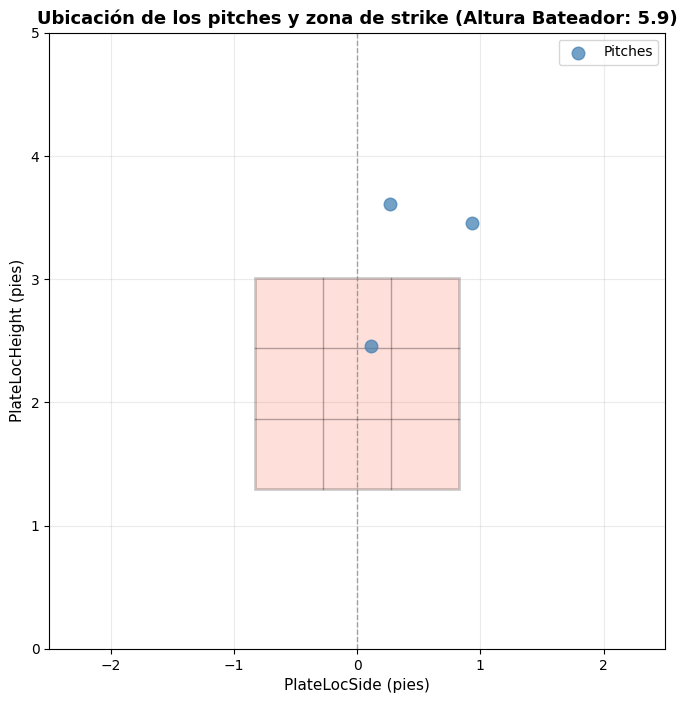

In [84]:
print(df_last_game_2025.head(6)[['PlateLocSide', 'PlateLocHeight']])
plot_pitches(df_last_game_2025.head(3),5.9)

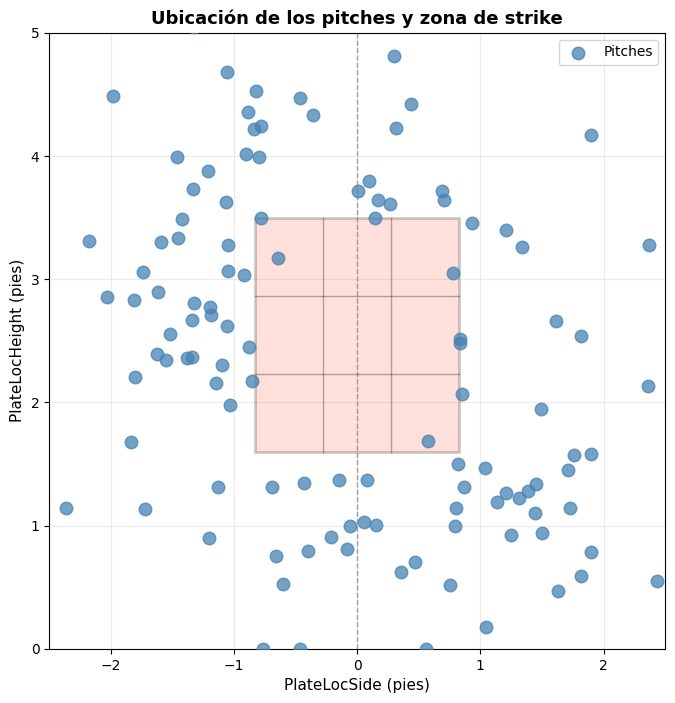

In [77]:
##  graficar pitcheos marcados strike
df_strike = df_last_game_2025[df_last_game_2025['PitchCall'] == 'BallCalled']
plot_pitches(df_strike)

# visualizar efectos de altura


In [114]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_altitude_pitch_movement(df,pitchType="Four-Seam"):
    """
    Plotea el movimiento horizontal (HorzBreak) vs el movimiento vertical (VertBreak) 
    coloreado por 'altitude_category' para visualizar el impacto de la altura en los lanzamientos.
    """
    # Detectar si la columna se llama VertBreak o InducedVertBreak
    vert_col = 'InducedVertBreak'
    
    fig, ax = plt.subplots(figsize=(10, 8))
    df_pitchType = df[df['AutoPitchType'] == pitchType]
    # Gráfico de dispersión diferenciando cada categoría de altitud por color
    sns.scatterplot(
        data=df_pitchType,
        x='HorzBreak',
        y=vert_col,
        hue='altitude_category',
        palette='Set2',
        alpha=0.75,
        s=65,
        ax=ax
    )
    
    # Líneas de referencia centrales
    ax.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.6)
    ax.axvline(0, color='gray', linestyle='--', linewidth=1, alpha=0.6)
    
    # Anotación explicativa sobre la estadística más afectada
    ax.set_title(
        'Impacto de la Altitud en el Movimiento de Pitcheos\n'
        f'(Estadística más afectada: Movimiento Vertical / {vert_col})', 
        fontsize=13, 
        fontweight='bold', 
        pad=15
    )
    ax.set_xlabel('Movimiento Horizontal / HorzBreak (pulgadas)', fontsize=11)
    ax.set_ylabel(f'Movimiento Vertical / {vert_col} (pulgadas)', fontsize=11)
    print("promedio  de movimiento vertical por grupo pitchtype",pitchType)
    for category, group in df_pitchType.groupby('altitude_category'):
        mean_vert_break = group[vert_col].mean()
        print(f"Categoría: {category}, Promedio de {vert_col}: {mean_vert_break:.2f} pulgadas")
    ax.grid(True, alpha=0.2, linestyle=':')
    ax.legend(title='Categoría de Altitud', bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.tight_layout()
    plt.show()

promedio  de movimiento vertical por grupo pitchtype Four-Seam
Categoría: Extreme Altitude, Promedio de InducedVertBreak: 12.87 pulgadas
Categoría: Medium Altitude, Promedio de InducedVertBreak: 14.21 pulgadas
Categoría: No Altitude, Promedio de InducedVertBreak: 16.86 pulgadas


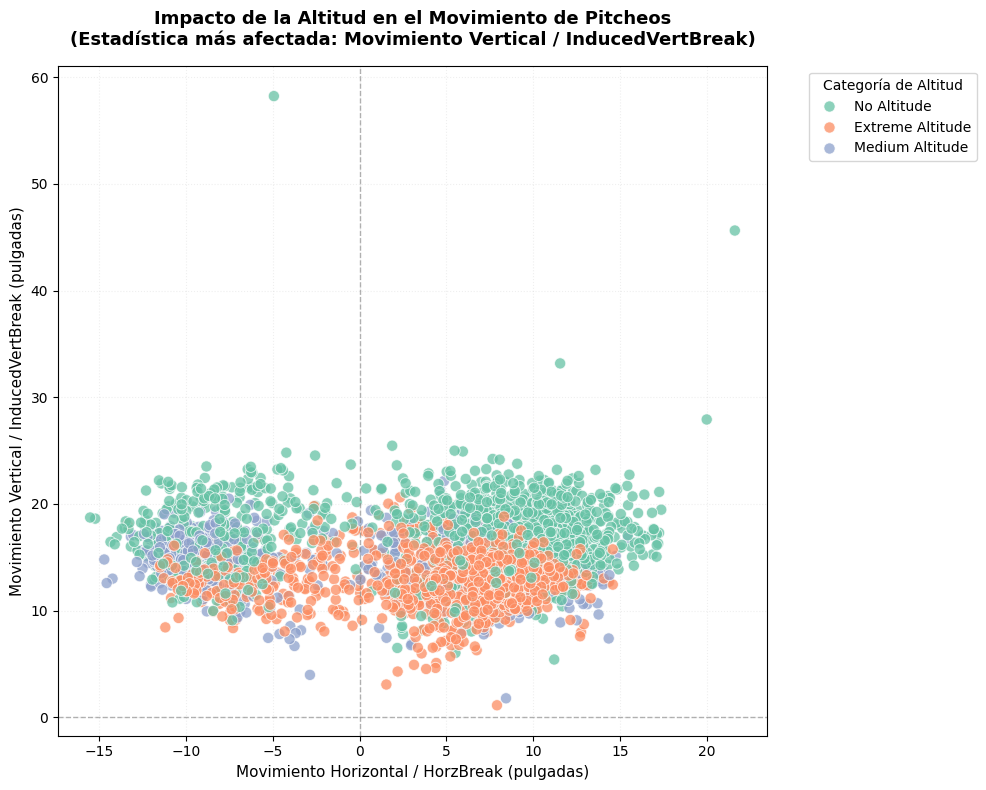

In [118]:
## visualizaremos pitcheos de bauer
#Four-Seam, Sinker, Cutter, Changeup, Splitter, Slider, Curveball,
df_bauer = df[df['pitcher_anon_id'] == 'pitcher_00619']
plot_altitude_pitch_movement(df.head(10000),pitchType="Four-Seam")

In [131]:
import numpy as np
import matplotlib.pyplot as plt


def plot_spin_axis(dataframe, pitch_type=None, bins=36, color_by=None):
    """Visualiza la distribución del eje de spin en grados de 0 a 360."""
    required_columns = ['SpinAxis']
    if pitch_type is not None:
        required_columns.append('AutoPitchType')

    missing_columns = [column for column in required_columns if column not in dataframe.columns]
    if missing_columns:
        raise ValueError(f'Faltan columnas necesarias: {missing_columns}')

    data = dataframe.copy()
    title_suffix = ''

    if pitch_type is not None:
        data = data[data['AutoPitchType'] == pitch_type]
        title_suffix = f' - {pitch_type}'

    data['SpinAxis'] = pd.to_numeric(data['SpinAxis'], errors='coerce') % 360
    spin_data = data.dropna(subset=['SpinAxis'])

    if spin_data.empty:
        raise ValueError('No hay valores válidos de SpinAxis para graficar.')

    if color_by == 'AutoPitchType' and 'AutoPitchType' in spin_data.columns:
        fig, axes = plt.subplots(
            1, 2,
            figsize=(15, 6),
            subplot_kw={'projection': [None, 'polar']}
        )
        histogram_axis = axes[0]
        polar_axis = axes[1]

        for label, group in spin_data.groupby('AutoPitchType'):
            histogram_axis.hist(
                group['SpinAxis'], bins=bins, range=(0, 360),
                alpha=0.45, label=f'{label} (n={len(group):,})'
            )
        histogram_axis.set_title('Distribución de SpinAxis')
        histogram_axis.set_xlabel('SpinAxis (grados)')
        histogram_axis.set_ylabel('Número de pitcheos')
        histogram_axis.set_xlim(0, 360)
        histogram_axis.grid(alpha=0.25)
        histogram_axis.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

        for label, group in spin_data.groupby('AutoPitchType'):
            angles = np.deg2rad(group['SpinAxis'].to_numpy())
            polar_axis.scatter(angles, np.ones(len(angles)), s=10, alpha=0.45, label=label)
        polar_axis.set_title('SpinAxis en círculo')
        polar_axis.set_theta_zero_location('N')
        polar_axis.set_theta_direction(-1)
        polar_axis.set_rticks([])
    else:
        angles_degrees = spin_data['SpinAxis'].to_numpy()
        angles_radians = np.deg2rad(angles_degrees)
        mean_angle = np.arctan2(np.sin(angles_radians).mean(), np.cos(angles_radians).mean())
        mean_angle_degrees = np.rad2deg(mean_angle) % 360

        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        histogram_axis, polar_axis = axes
        histogram_axis.hist(
            angles_degrees, bins=bins, range=(0, 360),
            color='steelblue', alpha=0.75, edgecolor='white'
        )
        histogram_axis.axvline(
            mean_angle_degrees, color='crimson', linestyle='--', linewidth=2,
            label=f'Media circular: {mean_angle_degrees:.1f} grados'
        )
        histogram_axis.set_title(f'Distribución de SpinAxis{title_suffix}')
        histogram_axis.set_xlabel('SpinAxis (grados)')
        histogram_axis.set_ylabel('Número de pitcheos')
        histogram_axis.set_xlim(0, 360)
        histogram_axis.grid(alpha=0.25)
        histogram_axis.legend()

        polar_axis = fig.add_subplot(1, 2, 2, projection='polar')
        polar_axis.scatter(angles_radians, np.ones(len(angles_radians)), s=12, alpha=0.4)
        polar_axis.plot([mean_angle], [1], marker='o', color='crimson', markersize=9)
        polar_axis.set_title(f'Media circular: {mean_angle_degrees:.1f} grados')
        polar_axis.set_theta_zero_location('N')
        polar_axis.set_theta_direction(-1)
        polar_axis.set_rticks([])

    fig.suptitle(f'Eje de spin de los pitcheos{title_suffix}', fontsize=14)
    plt.tight_layout()
    plt.show()


# Ejemplo general:
#plot_spin_axis(df.head(1000))

# Ejemplo para un tipo específico:
plot_spin_axis(df.head(1000), pitch_type='Fastball')

# Comparación por tipo de pitcheo:
# plot_spin_axis(df, color_by='AutoPitchType')

ValueError: No hay valores válidos de SpinAxis para graficar.

In [119]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_pitch_trajectory_profile(df, pitcher_id='pitcher_00619'):
    """
    Plotea un perfil lateral estimado de la trayectoria de los pitcheos 
    desde el punto de suelta hasta el home plate para un pitcher específico.
    """
    # Filtrar datos para el pitcher y asegurarnos de tener las columnas necesarias
    p_df = df[df['pitcher_anon_id'] == pitcher_id].copy()
    
    required_cols = ['AutoPitchType', 'RelHeight', 'PlateLocHeight', 'Extension']
    for col in required_cols:
        if col not in p_df.columns:
            print(f"Falta la columna {col} en el DataFrame.")
            return

    p_df = p_df.dropna(subset=required_cols)
    
    if p_df.empty:
        print(f"No hay datos suficientes para el pitcher {pitcher_id}.")
        return

    fig, ax = plt.subplots(figsize=(12, 7))
    
    # Colores distintivos para los pitcheos principales
    palette = sns.color_palette("Set1", n_colors=p_df['AutoPitchType'].nunique())
    pitch_colors = dict(zip(p_df['AutoPitchType'].unique(), palette))
    
    # Dibujar cada lanzamiento como una línea curva estimada desde la suelta hasta el plato
    for idx, row in p_df.iterrows():
        ptype = row['AutoPitchType']
        # Distancia aproximada de suelta (60.5 pies menos la extensión hacia el plato)
        release_dist = 60.5 - row['Extension']
        rel_h = row['RelHeight']
        plate_h = row['PlateLocHeight']
        
        # Generar puntos intermedios simulando una trayectoria parabólica con caída por gravedad/rompimiento
        x_vals = np.linspace(0, release_dist, 50) # 0 es el home plate, release_dist es la lomita
        
        # Curva cuadrática simple para ilustrar la bajada física
        # (Interpolación visual entre la altura de suelta en X=release_dist y la altura en plato X=0)
        # La gravedad hace que la curva no sea una línea recta perfecta.
        y_vals = plate_h + (rel_h - plate_h) * (x_vals / release_dist) ** 1.2
        
        ax.plot(x_vals, y_vals, color=pitch_colors.get(ptype, 'gray'), alpha=0.3, linewidth=1.5)

    # Graficar promedios o puntos clave por tipo de pitcheo para la leyenda
    sns.scatterplot(
        data=p_df,
        x=p_df['60.5'] - p_df['Extension'] if '60.5' in p_df else 60.5 - p_df['Extension'], # Distancia de suelta estimada
        y='RelHeight',
        hue='AutoPitchType',
        palette=pitch_colors,
        s=70,
        ax=ax,
        edgecolor='black',
        zorder=5
    )
    
    # Referencias del terreno
    ax.axvline(0, color='saddlebrown', linestyle='-', linewidth=4, label='Home Plate (0 pies)')
    ax.axvline(60.5, color='gray', linestyle='--', linewidth=1.5, label='Lomita / Placa (60.5 pies)')
    
    # Configuración de ejes
    ax.set_title(f'Perfil Lateral de Trayectoria - Pitcher: {pitcher_id}', fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel('Distancia desde el Home Plate (pies)', fontsize=11)
    ax.set_ylabel('Altura (pies)', fontsize=11)
    
    ax.set_xlim(-2, 65)
    ax.set_ylim(0, 8)
    ax.grid(True, alpha=0.2, linestyle=':')
    ax.legend(title='Tipo de Pitcheo', bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.tight_layout()
    plt.show()

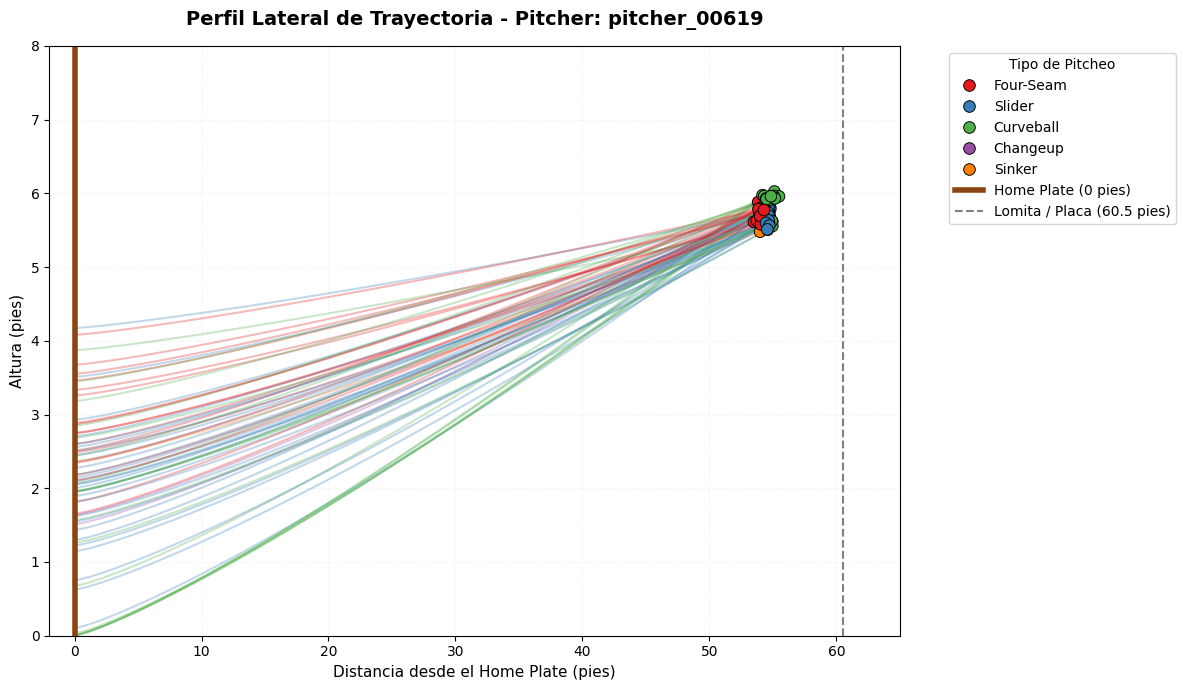

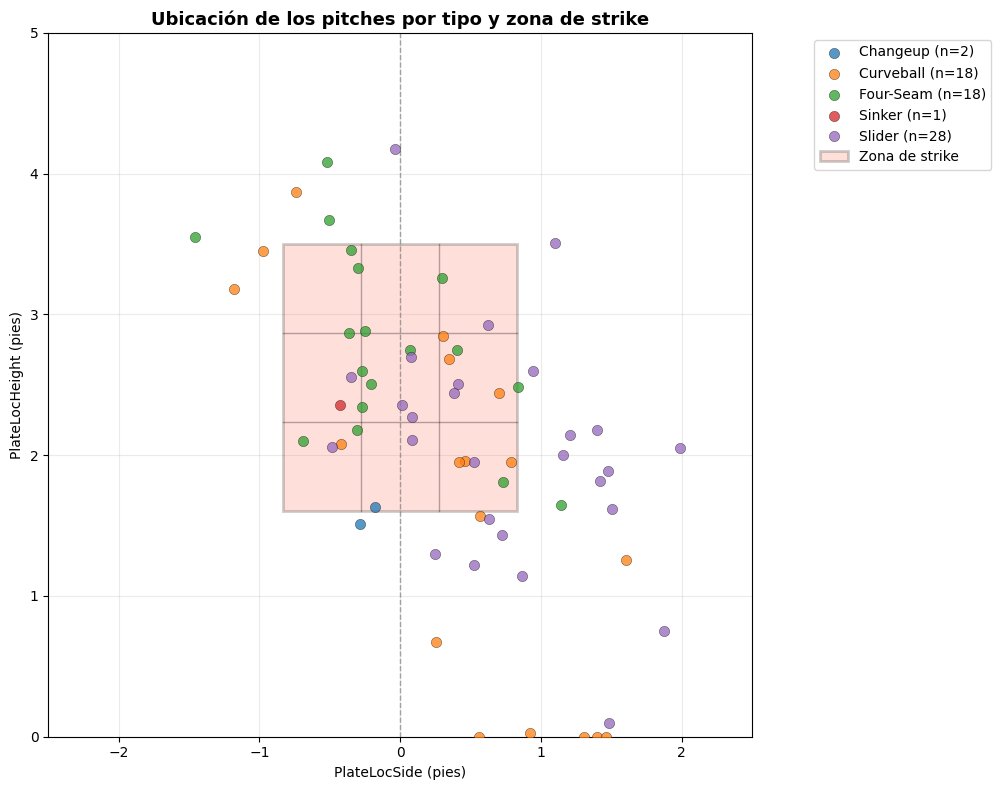

In [136]:
df_game_bauer =df[df['game_anon_id'] == 'game_001669'] 
df_game_bauer = df_game_bauer[df_game_bauer['pitcher_anon_id'] == 'pitcher_00619']
plot_pitch_trajectory_profile(df_game_bauer, pitcher_id='pitcher_00619')
plot_pitches(df_game_bauer)